# Supplementary figure. Pathway batch structure and diversity

Functional pathway alpha-diversity, distance matrices, PCoA ordination, and PERMANOVA for study-level batch effect versus clinical group.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist, squareform
from scipy.stats import mannwhitneyu
from skbio import DistanceMatrix
from skbio.diversity import beta_diversity
from skbio.diversity.alpha import shannon, simpson
from skbio.stats.ordination import pcoa

from config import (
    CLR_PSEUDO,
    DEFAULT_METADATA_PATH,
    DEFAULT_PATH_PATH,
    DIST_DIR,
    FIGURE_OUTPUT_DIR,
    META_COLS,
    MIN_BIOPROJECTS,
    MIN_PREVALENCE,
    UNWANTED_PATHWAY_COLS,
)
from common import (
    assign_group,
    benjamini_hochberg,
    confidence_ellipse,
    numeric_feature_frame,
    permanova_r2,
    prevalence_bioproject_filter,
    pval_to_stars,
    read_csv_with_run,
    to_relative,
)

FIG_DIR = FIGURE_OUTPUT_DIR / "Fig_S_pathway_batch_diversity"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DIST_DIR.mkdir(parents=True, exist_ok=True)

GROUP_ORDER = ["Healthy", "Caries (K02)", "Periodontitis (K05)", "K02+K05"]
PALETTE = {
    "Healthy": "#7DAF86",
    "Caries (K02)": "#C9A86C",
    "Periodontitis (K05)": "#7B80C0",
    "K02+K05": "#8DAAB8",
}

PATHWAY_SPECIAL_COLS = set(UNWANTED_PATHWAY_COLS) | {"UNGROUPED"}


## Load pathway profiles and metadata

In [2]:
path_raw = read_csv_with_run(DEFAULT_PATH_PATH).set_index("run")
metadata = read_csv_with_run(DEFAULT_METADATA_PATH).set_index("run")

common_runs = metadata.index.intersection(path_raw.index)
if len(common_runs) == 0:
    raise ValueError("No common runs between metadata and pathway table")

metadata = metadata.loc[common_runs].copy()
path_raw = path_raw.loc[common_runs].copy()

feature_cols = [
    col for col in path_raw.columns
    if col not in META_COLS
    and str(col) not in PATHWAY_SPECIAL_COLS
    and "|" not in str(col)
]
path_data = numeric_feature_frame(path_raw, feature_cols)
path_data[path_data < 0] = 0.0

metadata["group"] = metadata.apply(assign_group, axis=1)
metadata = metadata[metadata["group"].isin(GROUP_ORDER)].copy()
path_data = path_data.loc[metadata.index]

nonzero_samples = path_data.sum(axis=1) > 0
path_data = path_data.loc[nonzero_samples].copy()
metadata = metadata.loc[path_data.index].copy()

nonzero_features = path_data.sum(axis=0) > 0
path_data = path_data.loc[:, nonzero_features].copy()

metadata["group"] = pd.Categorical(metadata["group"], categories=GROUP_ORDER, ordered=True)

print(f"Samples: {len(metadata)}")
print(f"Pathway features: {path_data.shape[1]}")
print(f"Bioprojects: {metadata['bioproject'].nunique()}")
print(metadata["group"].value_counts().reindex(GROUP_ORDER).fillna(0).astype(int))


Samples: 514
Pathway features: 522
Bioprojects: 14
group
Healthy                204
Caries (K02)           149
Periodontitis (K05)    130
K02+K05                 31
Name: count, dtype: int64


## Pathway alpha-diversity

In [3]:
metadata["observed_pathways"] = (path_data > 0).sum(axis=1)
metadata["shannon_pathways"] = path_data.apply(lambda row: shannon(row.values), axis=1)
metadata["simpson_pathways"] = path_data.apply(lambda row: simpson(row.values), axis=1)

bp_group_counts = metadata.groupby("bioproject")["group"].nunique()
valid_bioprojects = bp_group_counts[bp_group_counts >= 2].index
metadata_alpha = metadata[metadata["bioproject"].isin(valid_bioprojects)].copy()

print(f"Bioprojects used for alpha panels: {len(valid_bioprojects)}")


Bioprojects used for alpha panels: 10


In [4]:
def alpha_test_table(metadata_alpha: pd.DataFrame) -> pd.DataFrame:
    rows = []
    metrics = ["observed_pathways", "shannon_pathways", "simpson_pathways"]
    bp_order = metadata_alpha["bioproject"].unique().tolist()

    for metric in metrics:
        for bp in bp_order:
            sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
            present_groups = [
                group for group in GROUP_ORDER
                if len(sub.loc[sub["group"] == group, metric].dropna()) >= 3
            ]
            if len(present_groups) < 2:
                continue

            for group1, group2 in combinations(present_groups, 2):
                values1 = sub.loc[sub["group"] == group1, metric].dropna()
                values2 = sub.loc[sub["group"] == group2, metric].dropna()
                if len(values1) < 3 or len(values2) < 3:
                    continue

                _, p_value = mannwhitneyu(values1, values2, alternative="two-sided")
                rows.append({
                    "metric": metric,
                    "bioproject": bp,
                    "group1": group1,
                    "group2": group2,
                    "p_value": p_value,
                })

    columns = ["metric", "bioproject", "group1", "group2", "p_value", "q_value"]
    test_df = pd.DataFrame(rows)
    if test_df.empty:
        return pd.DataFrame(columns=columns)

    test_df["q_value"] = benjamini_hochberg(test_df["p_value"].values)
    return test_df[columns]


alpha_tests = alpha_test_table(metadata_alpha)
alpha_tests_path = FIG_DIR / "pathway_alpha_mannwhitney_fdr.csv"
alpha_tests.to_csv(alpha_tests_path, index=False)

alpha_tests.sort_values("q_value").head(20) if not alpha_tests.empty else alpha_tests


,metric,bioproject,group1,group2,p_value,q_value
15,observed_pathways,PRJNA929548,Healthy,Caries (K02),8.798962e-07,0.000045
32,shannon_pathways,PRJNA929548,Healthy,Caries (K02),3.150043e-06,0.000080
49,simpson_pathways,PRJNA929548,Healthy,Caries (K02),9.076226e-06,0.000154
1,observed_pathways,PRJNA1057503,Healthy,Periodontitis (K05),4.754601e-04,0.006062
18,shannon_pathways,PRJNA1057503,Healthy,Periodontitis (K05),6.464646e-04,0.006594
37,simpson_pathways,PRJNA1057503,Caries (K02),Periodontitis (K05),4.322835e-03,0.026979
20,shannon_pathways,PRJNA1057503,Caries (K02),Periodontitis (K05),4.131445e-03,0.026979
3,observed_pathways,PRJNA1057503,Caries (K02),Periodontitis (K05),4.761074e-03,0.026979
35,simpson_pathways,PRJNA1057503,Healthy,Periodontitis (K05),3.718809e-03,0.026979
27,shannon_pathways,PRJNA478018,Healthy,Caries (K02),9.963134e-03,0.050812


/tmp/ipykernel_3840982/514243804.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


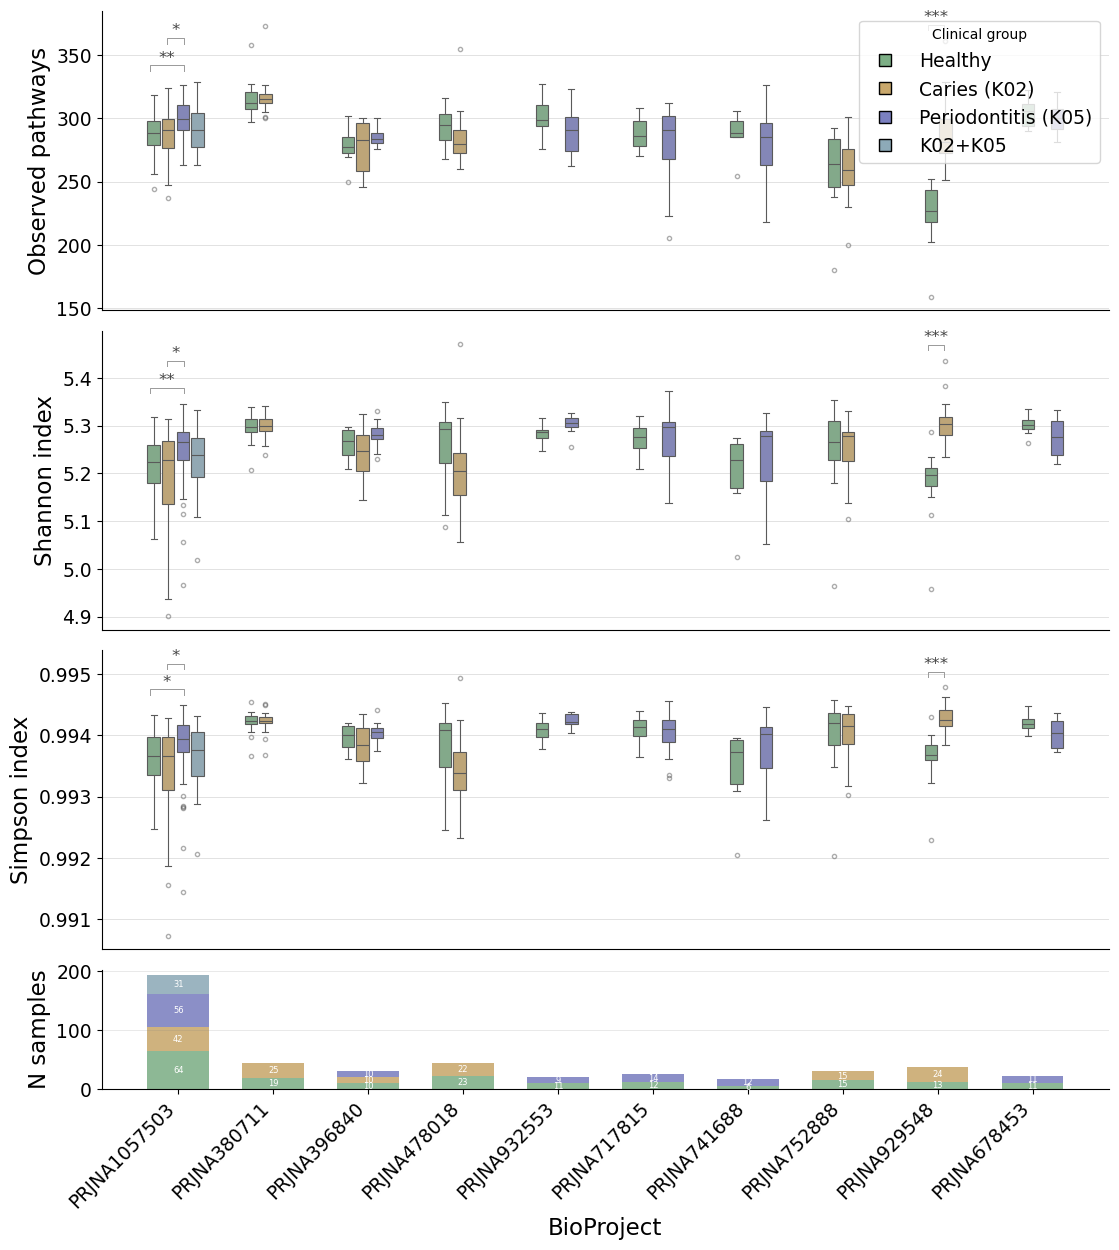

Saved alpha figure: results_article_configs/figures/Fig_S_pathway_batch_diversity/pathway_alpha_diversity.svg
Saved alpha figure: results_article_configs/figures/Fig_S_pathway_batch_diversity/pathway_alpha_diversity.png
Saved alpha tests: results_article_configs/figures/Fig_S_pathway_batch_diversity/pathway_alpha_mannwhitney_fdr.csv


In [5]:
SCALE = 1.5
FS = {
    "ylabel": 11 * SCALE,
    "xlabel": 11 * SCALE,
    "tick": 9 * SCALE,
    "tick_small": 9 * SCALE,
    "stars": 8 * SCALE,
    "bar_label": 4 * SCALE,
}

metrics = [
    ("observed_pathways", "Observed pathways"),
    ("shannon_pathways", "Shannon index"),
    ("simpson_pathways", "Simpson index"),
]

bp_order = metadata_alpha["bioproject"].unique().tolist()
bp_to_x = {bp: i for i, bp in enumerate(bp_order)}
n_bp = len(bp_order)

box_width = 0.6
box_gap = 0.15
step = box_width / len(GROUP_ORDER) * (1 + box_gap)
hue_offsets = {
    group: (i - (len(GROUP_ORDER) - 1) / 2) * step
    for i, group in enumerate(GROUP_ORDER)
}

fig = plt.figure(figsize=(max(n_bp * 1.2 + 1, 12), 14))
gs = fig.add_gridspec(4, 1, height_ratios=[3, 3, 3, 1.2], hspace=0.08)
alpha_axes = [fig.add_subplot(gs[i, 0]) for i in range(3)]
ax_n = fig.add_subplot(gs[3, 0])

for ax, (metric, ylabel) in zip(alpha_axes, metrics):
    boxplot_kwargs = dict(
        data=metadata_alpha,
        x="bioproject",
        y=metric,
        hue="group",
        hue_order=GROUP_ORDER,
        palette=PALETTE,
        order=bp_order,
        ax=ax,
        linewidth=0.8,
        width=box_width,
        flierprops=dict(marker="o", markersize=3, alpha=0.5),
        legend=False,
    )
    try:
        sns.boxplot(**boxplot_kwargs, gap=box_gap)
    except TypeError:
        sns.boxplot(**boxplot_kwargs)

    metric_min = metadata_alpha[metric].min()
    metric_max = metadata_alpha[metric].max()
    metric_range = metric_max - metric_min if metric_max != metric_min else 1

    for bp in bp_order:
        bp_x = bp_to_x[bp]
        sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
        present_groups = [
            group for group in GROUP_ORDER
            if len(sub.loc[sub["group"] == group, metric].dropna()) >= 3
        ]
        if len(present_groups) < 2:
            continue

        y_base = sub[metric].max() + metric_range * 0.04
        for group1, group2 in combinations(present_groups, 2):
            row = alpha_tests[
                (alpha_tests["metric"] == metric)
                & (alpha_tests["bioproject"] == bp)
                & (alpha_tests["group1"] == group1)
                & (alpha_tests["group2"] == group2)
            ]
            if row.empty:
                continue

            stars = pval_to_stars(row["q_value"].iloc[0])
            if stars is None:
                continue

            x1 = bp_x + hue_offsets[group1]
            x2 = bp_x + hue_offsets[group2]
            h = metric_range * 0.02
            ax.plot([x1, x1, x2, x2], [y_base, y_base + h, y_base + h, y_base], color="#999", linewidth=0.7)
            ax.text((x1 + x2) / 2, y_base + h, stars, ha="center", va="bottom", fontsize=FS["stars"], color="#444")
            y_base += metric_range * 0.10

    ax.set_ylabel(ylabel, fontsize=FS["ylabel"])
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelbottom=False, bottom=False)
    ax.tick_params(axis="y", labelsize=FS["tick"])
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", linewidth=0.4, alpha=0.4, color="gray")

for bp in bp_order:
    bp_x = bp_to_x[bp]
    sub = metadata_alpha[metadata_alpha["bioproject"] == bp]
    bottom = 0
    total = sum(len(sub.loc[sub["group"] == group]) for group in GROUP_ORDER)

    for group in GROUP_ORDER:
        n = len(sub.loc[sub["group"] == group])
        if n == 0:
            continue

        ax_n.bar(bp_x, n, bottom=bottom, width=0.65, color=PALETTE[group], alpha=0.88, linewidth=0)
        if n / max(total, 1) >= 0.08:
            ax_n.text(bp_x, bottom + n / 2, str(n), ha="center", va="center", fontsize=FS["bar_label"], color="white")
        bottom += n

ax_n.set_ylabel("N samples", fontsize=FS["ylabel"])
ax_n.set_xlabel("BioProject", fontsize=FS["xlabel"])
ax_n.tick_params(labelsize=FS["tick_small"])
ax_n.spines[["top", "right"]].set_visible(False)
ax_n.grid(axis="y", linewidth=0.4, alpha=0.3, color="gray")
ax_n.set_xticks(range(n_bp))
ax_n.set_xticklabels(bp_order, rotation=45, ha="right", fontsize=FS["tick_small"])

handles = [
    plt.Line2D([0], [0], marker="s", linestyle="", markersize=8, markerfacecolor=PALETTE[group], markeredgecolor="black", label=group)
    for group in GROUP_ORDER
]
alpha_axes[0].legend(handles=handles, title="Clinical group", loc="upper right", frameon=True, fontsize=FS["tick_small"])

plt.tight_layout()

out_alpha_svg = FIG_DIR / "pathway_alpha_diversity.svg"
out_alpha_png = FIG_DIR / "pathway_alpha_diversity.png"
fig.savefig(out_alpha_svg, bbox_inches="tight", transparent=True)
fig.savefig(out_alpha_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved alpha figure: {out_alpha_svg}")
print(f"Saved alpha figure: {out_alpha_png}")
print(f"Saved alpha tests: {alpha_tests_path}")


## Pathway beta-diversity distances

In [6]:
keep_features = prevalence_bioproject_filter(
    path_data.values,
    metadata["bioproject"].values,
    min_prevalence=MIN_PREVALENCE,
    min_bioprojects=MIN_BIOPROJECTS,
)
path_beta = path_data.loc[:, keep_features].copy()

if path_beta.shape[1] == 0:
    raise ValueError("No pathway features remain after prevalence and bioproject filters")

nonzero_samples = path_beta.sum(axis=1) > 0
path_beta = path_beta.loc[nonzero_samples].copy()
metadata_beta = metadata.loc[path_beta.index].copy()

path_rel = pd.DataFrame(
    to_relative(path_beta.values),
    index=path_beta.index,
    columns=path_beta.columns,
)

path_bc_input = np.sqrt(path_rel)
bc_dm = beta_diversity(
    metric="braycurtis",
    counts=path_bc_input.values,
    ids=path_bc_input.index.tolist(),
)
bc_df = pd.DataFrame(bc_dm.data, index=bc_dm.ids, columns=bc_dm.ids)
bc_path = DIST_DIR / "bray_curtis_pathways_filtered_closed.csv"
bc_df.to_csv(bc_path)

path_pc = path_rel + CLR_PSEUDO
path_pc = path_pc.div(path_pc.sum(axis=1), axis=0)
clr_path = np.log(path_pc)
clr_path = clr_path.subtract(clr_path.mean(axis=1), axis=0)

aitchison_dist = squareform(pdist(clr_path.values, metric="euclidean"))
at_dm = DistanceMatrix(aitchison_dist, ids=clr_path.index.tolist())
at_df = pd.DataFrame(at_dm.data, index=at_dm.ids, columns=at_dm.ids)
at_path = DIST_DIR / "aitchison_pathways_filtered_closed.csv"
at_df.to_csv(at_path)

print(f"Samples used for beta-diversity: {len(metadata_beta)}")
print(f"Pathways after beta filters: {path_beta.shape[1]}")
print(f"Saved distance matrix: {bc_path}")
print(f"Saved distance matrix: {at_path}")


Samples used for beta-diversity: 514
Pathways after beta filters: 337
Saved distance matrix: /srv/common/microbime_data/distances/bray_curtis_pathways_filtered_closed.csv
Saved distance matrix: /srv/common/microbime_data/distances/aitchison_pathways_filtered_closed.csv


## PCoA and PERMANOVA

In [7]:
bc_pcoa = pcoa(bc_dm)
at_pcoa = pcoa(at_dm)

bc_coords = bc_pcoa.samples[["PC1", "PC2"]].rename(columns={"PC1": "bc_PC1", "PC2": "bc_PC2"})
at_coords = at_pcoa.samples[["PC1", "PC2"]].rename(columns={"PC1": "at_PC1", "PC2": "at_PC2"})
beta_meta = metadata_beta.join(bc_coords).join(at_coords)

bc_var = bc_pcoa.proportion_explained
at_var = at_pcoa.proportion_explained

common_ids = [run for run in bc_dm.ids if run in beta_meta.index]
meta_perm = beta_meta.loc[common_ids]

bc_dm_f = DistanceMatrix(np.ascontiguousarray(bc_dm.filter(common_ids).data), ids=common_ids)
at_dm_f = DistanceMatrix(np.ascontiguousarray(at_dm.filter(common_ids).data), ids=common_ids)

perm_bc_bp = permanova_r2(bc_dm_f, meta_perm["bioproject"])
perm_bc_group = permanova_r2(bc_dm_f, meta_perm["group"])
perm_at_bp = permanova_r2(at_dm_f, meta_perm["bioproject"])
perm_at_group = permanova_r2(at_dm_f, meta_perm["group"])

print(f"Bray-Curtis PC1={bc_var.iloc[0]:.1%}, PC2={bc_var.iloc[1]:.1%}")
print(f"Aitchison PC1={at_var.iloc[0]:.1%}, PC2={at_var.iloc[1]:.1%}")

print("Bray-Curtis:")
print(f"  study R2={perm_bc_bp['R2']:.4f}, p={perm_bc_bp['p_value']:.3f}")
print(f"  group R2={perm_bc_group['R2']:.4f}, p={perm_bc_group['p_value']:.3f}")
print(f"  study/group R2 ratio = {perm_bc_bp['R2'] / max(perm_bc_group['R2'], 1e-6):.1f}x")

print("Aitchison:")
print(f"  study R2={perm_at_bp['R2']:.4f}, p={perm_at_bp['p_value']:.3f}")
print(f"  group R2={perm_at_group['R2']:.4f}, p={perm_at_group['p_value']:.3f}")
print(f"  study/group R2 ratio = {perm_at_bp['R2'] / max(perm_at_group['R2'], 1e-6):.1f}x")


/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:164: RuntimeWarning: EIGH: since no value for dimensions is specified, PCoA for all dimensions will be computed, which may result in long computation time if the original distance matrix is large.
  warn(
/home/jupyter-seraph/.conda/envs/pyEDA_env/lib/python3.14/site-packages/skbio/stats/ordination/_principal_coordinate_analysis.py:282: RuntimeWarning: The result contains negative eigenvalues that are large in magnitude, which may suggest result inaccuracy. See Notes for details. The negative-most eigenvalue is -0.03210761864904339 whereas the largest positive one is 1.0942541330370232.
  warn(


Bray-Curtis PC1=22.8%, PC2=12.0%
Aitchison PC1=13.9%, PC2=9.9%
Bray-Curtis:
  study R2=0.3395, p=0.001
  group R2=0.0374, p=0.001
  study/group R2 ratio = 9.1x
Aitchison:
  study R2=0.2188, p=0.001
  group R2=0.0255, p=0.001
  study/group R2 ratio = 8.6x


## Pathway ordination plot

/tmp/ipykernel_3840982/51283819.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for label, sub in data.groupby(color_col):


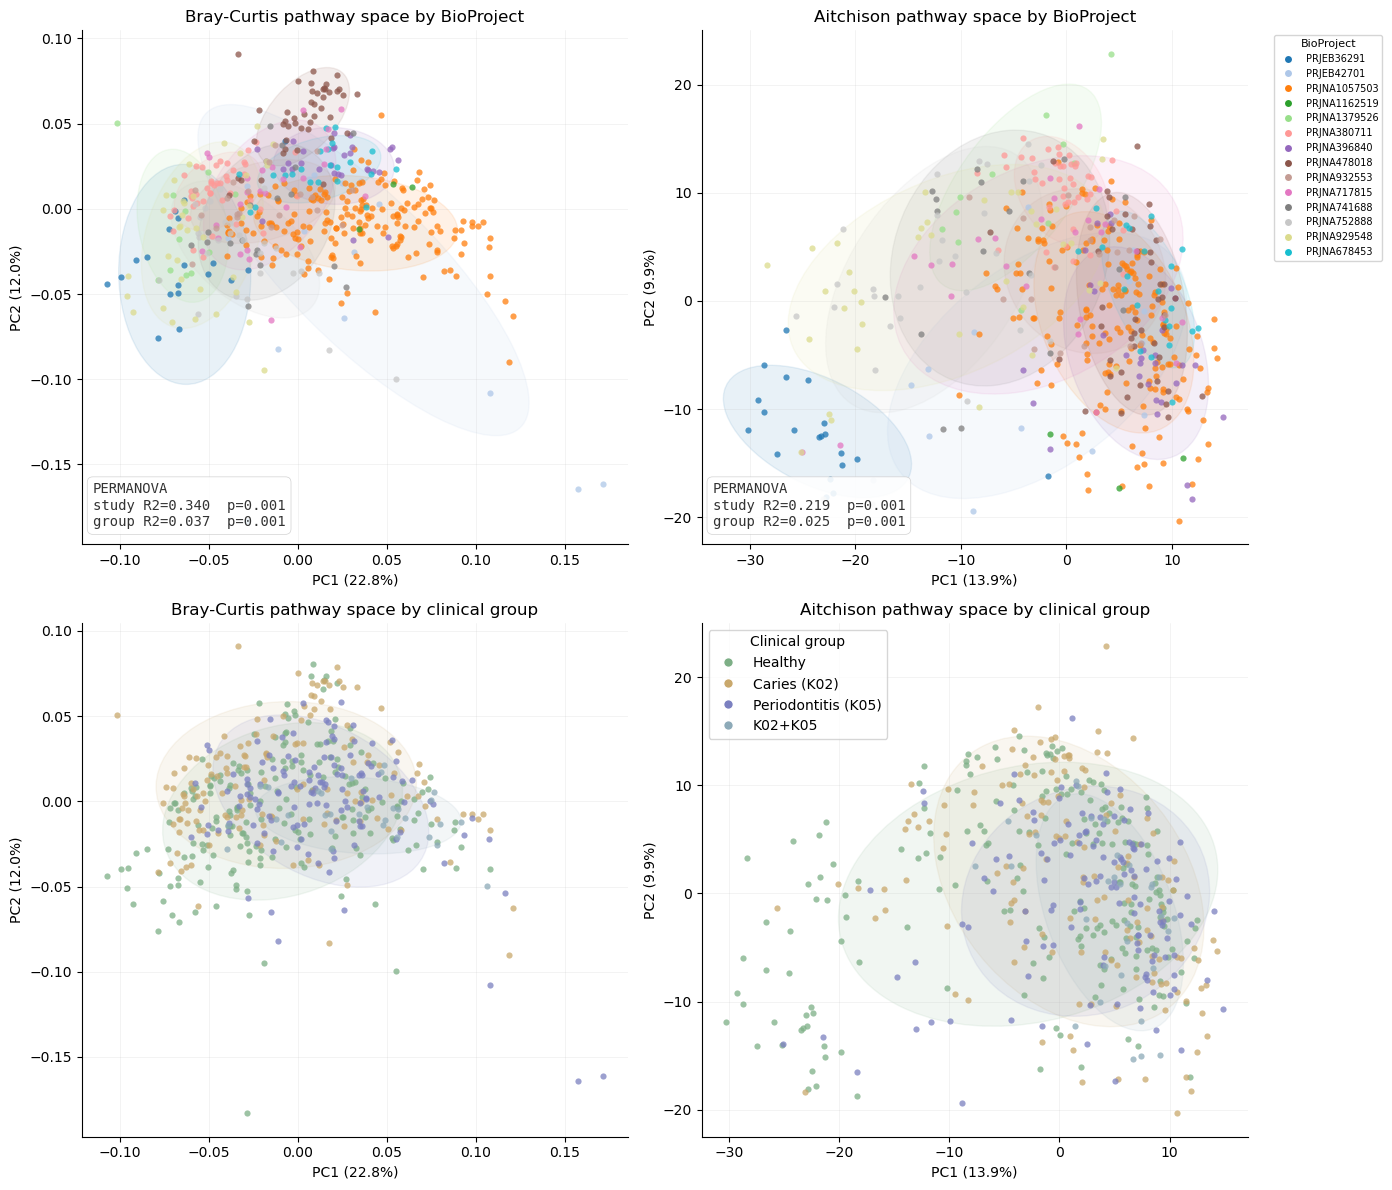

Saved beta figure: results_article_configs/figures/Fig_S_pathway_batch_diversity/pathway_beta_ordination.svg
Saved beta figure: results_article_configs/figures/Fig_S_pathway_batch_diversity/pathway_beta_ordination.png


In [8]:
def permanova_label(study_result: dict, group_result: dict) -> str:
    return (
        "PERMANOVA\n"
        f"study R2={study_result['R2']:.3f}  p={study_result['p_value']:.3f}\n"
        f"group R2={group_result['R2']:.3f}  p={group_result['p_value']:.3f}"
    )


def plot_pcoa_panel(
    ax,
    data: pd.DataFrame,
    x_col: str,
    y_col: str,
    color_col: str,
    color_map: dict,
    xlabel: str,
    ylabel: str,
    title: str = "",
    perm_text: str | None = None,
) -> None:
    for label, sub in data.groupby(color_col):
        if label not in color_map:
            continue
        color = color_map[label]
        ax.scatter(sub[x_col], sub[y_col], c=[color], s=20, alpha=0.75, linewidths=0, zorder=3)
        confidence_ellipse(
            sub[x_col].values,
            sub[y_col].values,
            ax,
            edgecolor=color,
            facecolor=color,
            alpha=0.10,
            linewidth=1.0,
        )

    if perm_text is not None:
        ax.text(
            0.02,
            0.03,
            perm_text,
            transform=ax.transAxes,
            fontsize=10,
            va="bottom",
            ha="left",
            color="#333",
            fontfamily="monospace",
            bbox=dict(boxstyle="round,pad=0.4", fc="white", ec="#ccc", lw=0.5, alpha=0.9),
        )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(linewidth=0.4, alpha=0.25)


bp_order = beta_meta["bioproject"].astype(str).unique().tolist()
bp_cmap = plt.cm.tab20
bp_colors = {bp: bp_cmap(i / max(len(bp_order), 1)) for i, bp in enumerate(bp_order)}

label_bc = permanova_label(perm_bc_bp, perm_bc_group)
label_at = permanova_label(perm_at_bp, perm_at_group)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.patch.set_facecolor("none")

plot_pcoa_panel(
    axes[0, 0],
    beta_meta,
    "bc_PC1",
    "bc_PC2",
    "bioproject",
    bp_colors,
    xlabel=f"PC1 ({bc_var.iloc[0]:.1%})",
    ylabel=f"PC2 ({bc_var.iloc[1]:.1%})",
    title="Bray-Curtis pathway space by BioProject",
    perm_text=label_bc,
)
plot_pcoa_panel(
    axes[0, 1],
    beta_meta,
    "at_PC1",
    "at_PC2",
    "bioproject",
    bp_colors,
    xlabel=f"PC1 ({at_var.iloc[0]:.1%})",
    ylabel=f"PC2 ({at_var.iloc[1]:.1%})",
    title="Aitchison pathway space by BioProject",
    perm_text=label_at,
)
plot_pcoa_panel(
    axes[1, 0],
    beta_meta,
    "bc_PC1",
    "bc_PC2",
    "group",
    PALETTE,
    xlabel=f"PC1 ({bc_var.iloc[0]:.1%})",
    ylabel=f"PC2 ({bc_var.iloc[1]:.1%})",
    title="Bray-Curtis pathway space by clinical group",
)
plot_pcoa_panel(
    axes[1, 1],
    beta_meta,
    "at_PC1",
    "at_PC2",
    "group",
    PALETTE,
    xlabel=f"PC1 ({at_var.iloc[0]:.1%})",
    ylabel=f"PC2 ({at_var.iloc[1]:.1%})",
    title="Aitchison pathway space by clinical group",
)

handles_group = [
    plt.Line2D([0], [0], marker="o", linestyle="", markersize=7, markerfacecolor=PALETTE[group], markeredgecolor="white", label=group)
    for group in GROUP_ORDER
]
axes[1, 1].legend(handles=handles_group, title="Clinical group", loc="best", frameon=True)

handles_bp = [
    plt.Line2D([0], [0], marker="o", linestyle="", markersize=6, markerfacecolor=bp_colors[bp], markeredgecolor="white", label=bp)
    for bp in bp_order
]
axes[0, 1].legend(
    handles=handles_bp,
    title="BioProject",
    bbox_to_anchor=(1.04, 1.0),
    loc="upper left",
    frameon=True,
    fontsize=7,
    title_fontsize=8,
)

plt.tight_layout()

out_beta_svg = FIG_DIR / "pathway_beta_ordination.svg"
out_beta_png = FIG_DIR / "pathway_beta_ordination.png"
fig.savefig(out_beta_svg, bbox_inches="tight", transparent=True)
fig.savefig(out_beta_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved beta figure: {out_beta_svg}")
print(f"Saved beta figure: {out_beta_png}")
